# Notebook 07 — Dengue Anomaly Detection and Outbreak Identification

**RiskWeave | Sri Lanka**

## Objective
Detect unusually high district-level dengue observations using historical dengue counts.

**Scope:** This first version uses dengue counts only. Weather anomaly detection is not included yet.

**Important:** A statistical anomaly is not automatically a confirmed dengue outbreak. Until validated against official epidemiological evidence and outbreak definitions, outputs are labelled *candidate high anomalies*.

### Method
1. Validate the cleaned district-week dataset.
2. Inspect reporting-period lengths.
3. Convert counts to a seven-day-equivalent rate to account for 6-, 7-, and 8-day reporting periods.
4. Calculate a district-specific baseline from the preceding 52 reporting periods, excluding the current period.
5. Calculate a robust score using the rolling median and median absolute deviation (MAD).
6. Flag candidate high anomalies using a provisional threshold of 3.5.
7. Review and export results.

The threshold is an exploratory statistical screening heuristic, not an official Sri Lankan outbreak threshold.

## 1. Import libraries and locate the RiskWeave project

In [32]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

cwd = Path.cwd()
if cwd.name.lower() == "notebooks":
    PROJECT_ROOT = cwd.parent
elif (cwd / "data").exists():
    PROJECT_ROOT = cwd
else:
    raise FileNotFoundError(
        "Open this notebook from RiskWeave/notebooks or the project root."
    )

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "dengue_weather_weekly_25_districts.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "anomaly_detection"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Input:", DATA_PATH)
print("Output:", OUTPUT_DIR)

Project root: c:\Users\Nethmi\Documents\GitHub\RiskWeave
Input: c:\Users\Nethmi\Documents\GitHub\RiskWeave\data\processed\dengue_weather_weekly_25_districts.csv
Output: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\anomaly_detection


## 2. Load the processed dataset

This dataset contains aligned district-week dengue counts and weather summaries. This notebook uses only the dengue count and reporting dates.

In [33]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

required_cols = ["district_key", "week_start", "week_end", "dengue_cases"]
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

df["week_start"] = pd.to_datetime(df["week_start"], errors="coerce")
df["week_end"] = pd.to_datetime(df["week_end"], errors="coerce")
df["dengue_cases"] = pd.to_numeric(df["dengue_cases"], errors="coerce")
df["district_key"] = df["district_key"].astype("string").str.strip().str.lower()

print("Shape:", df.shape)
print("Districts:", df["district_key"].nunique())
print("Date range:", df["week_start"].min(), "to", df["week_end"].max())
display(df[required_cols].head())

Shape: (24775, 27)
Districts: 25
Date range: 2006-12-23 00:00:00 to 2025-12-19 00:00:00


,district_key,week_start,week_end,dengue_cases
0,ampara,2006-12-23,2006-12-29,0
1,ampara,2006-12-30,2007-01-05,0
2,ampara,2007-01-06,2007-01-12,0
3,ampara,2007-01-13,2007-01-19,0
4,ampara,2007-01-20,2007-01-26,0


## 3. Data-quality checks

Do not silently remove suspicious records. Stop and investigate if required checks fail.

In [34]:
df = df.sort_values(["district_key", "week_start"]).reset_index(drop=True)

quality = {
    "rows": len(df),
    "districts": df["district_key"].nunique(),
    "missing_district": df["district_key"].isna().sum(),
    "missing_week_start": df["week_start"].isna().sum(),
    "missing_week_end": df["week_end"].isna().sum(),
    "missing_dengue_cases": df["dengue_cases"].isna().sum(),
    "negative_dengue_cases": (df["dengue_cases"] < 0).sum(),
    "duplicate_district_week_start": df.duplicated(["district_key", "week_start"]).sum(),
    "week_end_before_week_start": (df["week_end"] < df["week_start"]).sum()
}
display(pd.DataFrame({"check": quality.keys(), "value": quality.values()}))

if any(quality[k] > 0 for k in [
    "missing_district", "missing_week_start", "missing_week_end",
    "missing_dengue_cases", "negative_dengue_cases",
    "duplicate_district_week_start", "week_end_before_week_start"
]):
    raise ValueError("Data-quality issue found. Review before continuing.")

print("Required data-quality checks passed.")

,check,value
0,rows,24775
1,districts,25
2,missing_district,0
3,missing_week_start,0
4,missing_week_end,0
5,missing_dengue_cases,0
6,negative_dengue_cases,0
7,duplicate_district_week_start,0
8,week_end_before_week_start,0


Required data-quality checks passed.


## 4. Inspect reporting-period lengths

The source includes 6-, 7-, and 8-day reporting periods. We calculate a seven-day-equivalent rate for comparability. The original `dengue_cases` column remains unchanged.

In [35]:
df["period_days"] = (df["week_end"] - df["week_start"]).dt.days + 1

display(
    df["period_days"].value_counts().sort_index()
      .rename_axis("period_days").reset_index(name="records")
)

if (df["period_days"] <= 0).any():
    raise ValueError("Non-positive reporting period found.")

df["cases_per_7_days"] = df["dengue_cases"] / df["period_days"] * 7

display(df[[
    "district_key", "week_start", "week_end",
    "period_days", "dengue_cases", "cases_per_7_days"
]].head())

,period_days,records
0,6,25
1,7,24725
2,8,25


,district_key,week_start,week_end,period_days,dengue_cases,cases_per_7_days
0,ampara,2006-12-23,2006-12-29,7,0,0.0
1,ampara,2006-12-30,2007-01-05,7,0,0.0
2,ampara,2007-01-06,2007-01-12,7,0,0.0
3,ampara,2007-01-13,2007-01-19,7,0,0.0
4,ampara,2007-01-20,2007-01-26,7,0,0.0


## 5. Explore district-level dengue patterns

Review historical peaks; do not remove them merely because they are extreme.

,count,mean,median,std,max
district_key,,,,,
colombo,991,176.287588,126.0,202.967592,1972
gampaha,991,103.326942,55.0,192.109996,2631
kandy,991,67.141271,38.0,102.342810,1062
kalutara,991,49.005045,31.0,68.334405,703
jaffna,991,45.315843,18.0,91.300393,931
kurunegala,991,42.042381,25.0,62.356633,681
ratnapura,991,39.721493,25.0,63.148623,920
kegalle,991,34.451060,20.0,62.420902,807
batticaloa,991,33.425832,15.0,51.238443,384


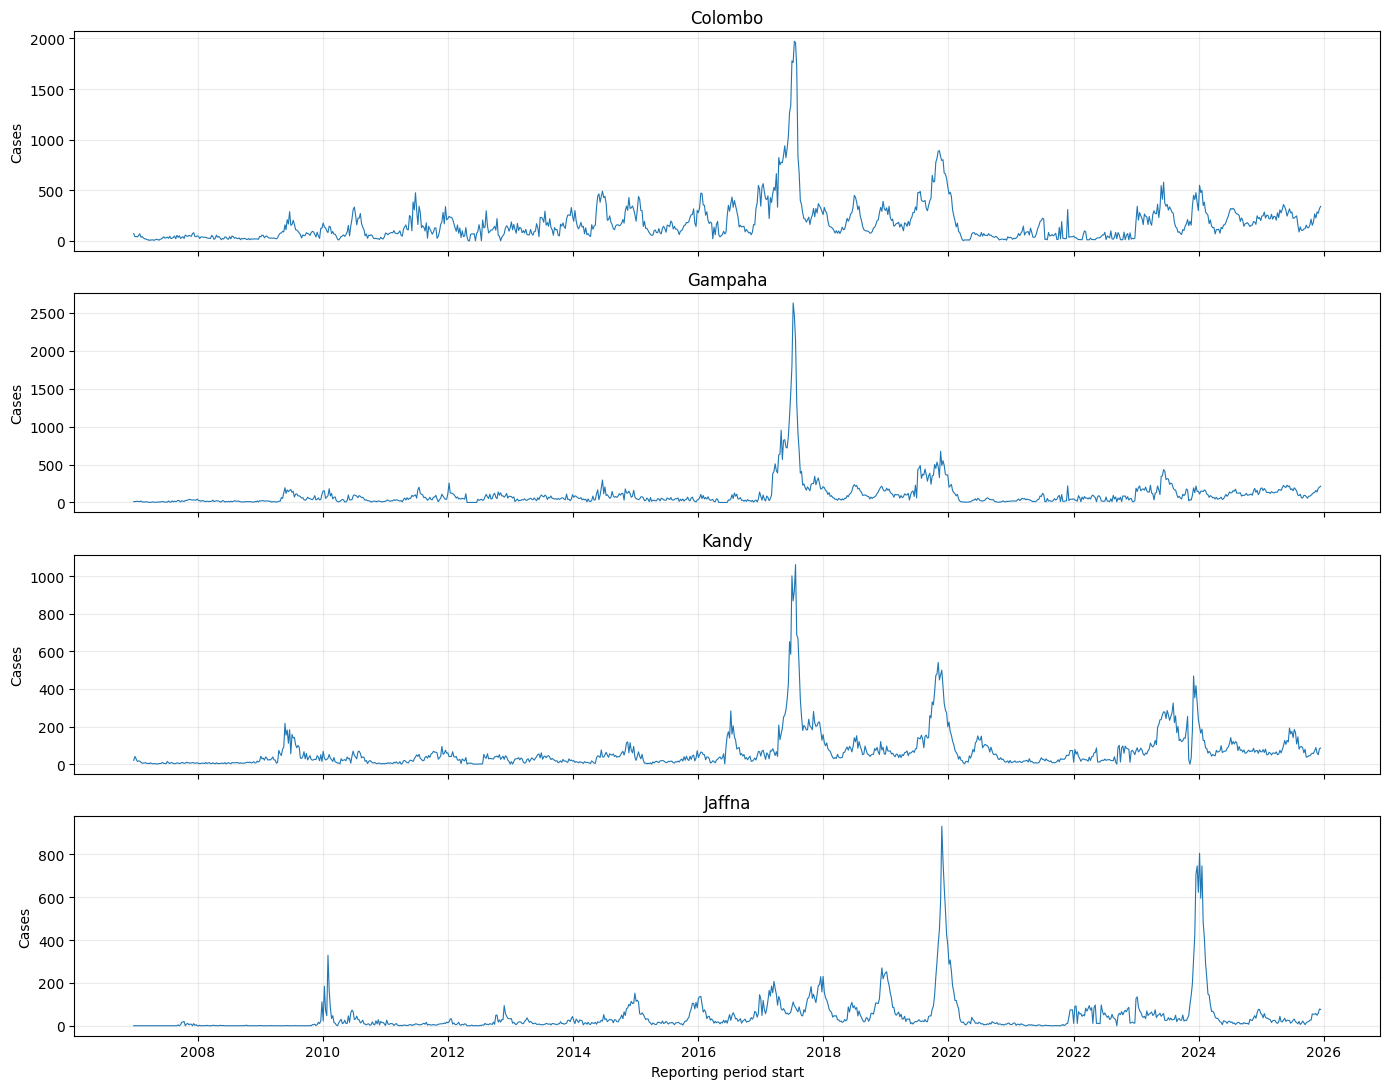

In [36]:
display(
    df.groupby("district_key")["dengue_cases"]
      .agg(["count", "mean", "median", "std", "max"])
      .sort_values("mean", ascending=False)
)

selected_districts = ["colombo", "gampaha", "kandy", "jaffna"]
fig, axes = plt.subplots(len(selected_districts), 1, figsize=(14, 11), sharex=True)

for ax, district in zip(axes, selected_districts):
    part = df[df["district_key"] == district]
    ax.plot(part["week_start"], part["dengue_cases"], linewidth=0.8)
    ax.set_title(district.title())
    ax.set_ylabel("Cases")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Reporting period start")
plt.tight_layout()
plt.show()

## 6. Calculate a district-specific historical baseline

For each district, the baseline uses the **previous 52 reporting periods**, excluding the current observation with `shift(1)`. At least 26 previous observations are required.

We use the median and median absolute deviation (MAD), which are less sensitive to extreme values than the mean and standard deviation.

This is a trailing baseline, not a seasonally matched baseline. Seasonal effects may influence the results and must be evaluated later.

In [37]:
WINDOW_PERIODS = 52
MIN_BASELINE_PERIODS = 26

df["baseline_median_52"] = (
    df.groupby("district_key")["cases_per_7_days"]
      .transform(lambda s: s.shift(1).rolling(
          WINDOW_PERIODS, min_periods=MIN_BASELINE_PERIODS
      ).median())
)

def previous_rolling_mad(series):
    previous = series.shift(1)

    def calculate_mad(values):
        median = np.median(values)
        return np.median(np.abs(values - median))

    return previous.rolling(
        WINDOW_PERIODS, min_periods=MIN_BASELINE_PERIODS
    ).apply(calculate_mad, raw=True)

df["baseline_mad_52"] = (
    df.groupby("district_key")["cases_per_7_days"]
      .transform(previous_rolling_mad)
)

display(df.groupby("district_key").tail(2)[[
    "district_key", "week_start", "cases_per_7_days",
    "baseline_median_52", "baseline_mad_52"
]])

,district_key,week_start,cases_per_7_days,baseline_median_52,baseline_mad_52
989,ampara,2025-12-06,22.0,14.0,3.0
990,ampara,2025-12-13,18.0,14.0,3.0
1980,anuradhapura,2025-12-06,12.0,9.5,3.5
1981,anuradhapura,2025-12-13,13.0,9.5,3.0
2971,badulla,2025-12-06,18.0,16.0,4.5
2972,badulla,2025-12-13,25.0,16.0,4.5
3962,batticaloa,2025-12-06,14.0,29.5,20.5
3963,batticaloa,2025-12-13,20.0,28.5,19.5
4953,colombo,2025-12-06,318.0,234.0,40.0
4954,colombo,2025-12-13,340.0,234.0,42.0


## 7. Calculate robust anomaly scores

\[
\text{Robust score} =
\frac{x - \text{historical median}}
{1.4826 \times \text{historical MAD}}
\]

If historical MAD is zero, the score is left missing. We do not divide by zero or manufacture an anomaly score.

In [38]:
MAD_SCALE = 1.4826
df["robust_anomaly_score"] = np.nan

valid_mad = (
    df["baseline_median_52"].notna()
    & df["baseline_mad_52"].notna()
    & (df["baseline_mad_52"] > 0)
)

df.loc[valid_mad, "robust_anomaly_score"] = (
    df.loc[valid_mad, "cases_per_7_days"]
    - df.loc[valid_mad, "baseline_median_52"]
) / (MAD_SCALE * df.loc[valid_mad, "baseline_mad_52"])

df["zero_mad_baseline"] = (
    df["baseline_mad_52"].notna()
    & (df["baseline_mad_52"] == 0)
)

display(df[[
    "district_key", "week_start", "cases_per_7_days",
    "baseline_median_52", "baseline_mad_52",
    "robust_anomaly_score", "zero_mad_baseline"
]].tail(10))

,district_key,week_start,cases_per_7_days,baseline_median_52,baseline_mad_52,robust_anomaly_score,zero_mad_baseline
24765,vavuniya,2025-10-11,2.0,2.0,1.0,0.000000,False
24766,vavuniya,2025-10-18,0.0,2.0,1.0,-1.348982,False
24767,vavuniya,2025-10-25,1.0,2.0,1.0,-0.674491,False
24768,vavuniya,2025-11-01,1.0,2.0,1.0,-0.674491,False
24769,vavuniya,2025-11-08,2.0,2.0,1.0,0.000000,False
24770,vavuniya,2025-11-15,0.0,2.0,1.0,-1.348982,False
24771,vavuniya,2025-11-22,0.0,2.0,1.0,-1.348982,False
24772,vavuniya,2025-11-29,1.0,2.0,1.0,-0.674491,False
24773,vavuniya,2025-12-06,2.0,2.0,1.0,0.000000,False
24774,vavuniya,2025-12-13,3.0,2.0,1.0,0.674491,False


In [39]:
# Overall robust anomaly score diagnostics

print("Total observations:", len(df))

print(
    "Missing robust scores:",
    df["robust_anomaly_score"].isna().sum()
)

print(
    "Zero MAD baselines:",
    df["zero_mad_baseline"].sum()
)

print("\nRobust score statistics:")

display(
    df["robust_anomaly_score"].describe()
)

print("\nTen highest robust anomaly scores:")

display(
    df.nlargest(10, "robust_anomaly_score")[
        [
            "district_key",
            "week_start",
            "dengue_cases",
            "cases_per_7_days",
            "baseline_median_52",
            "baseline_mad_52",
            "robust_anomaly_score"
        ]
    ]
)

Total observations: 24775
Missing robust scores: 3017
Zero MAD baselines: 1717

Robust score statistics:


count    21758.000000
mean         0.967432
std          3.801188
min         -3.170107
25%         -0.674491
50%          0.000000
75%          1.348982
max        234.048294
Name: robust_anomaly_score, dtype: float64


Ten highest robust anomaly scores:


,district_key,week_start,dengue_cases,cases_per_7_days,baseline_median_52,baseline_mad_52,robust_anomaly_score
23942,vavuniya,2010-01-02,174,174.0,0.5,0.5,234.048294
14654,mannar,2021-12-04,63,63.0,0.5,0.5,84.311345
23327,trincomalee,2017-03-18,435,435.0,5.5,3.5,82.769652
23326,trincomalee,2017-03-11,396,396.0,5.5,3.5,75.253898
23328,trincomalee,2017-03-25,425,425.0,5.5,4.0,70.737218
23329,trincomalee,2017-04-01,404,404.0,5.5,4.5,59.729904
23943,vavuniya,2010-01-09,82,82.0,1.0,1.0,54.633752
23324,trincomalee,2017-02-25,273,273.0,5.0,3.5,51.646721
3511,batticaloa,2017-04-15,384,384.0,7.0,5.0,50.856603
3090,batticaloa,2009-03-21,36,36.0,0.5,0.5,47.888844


## 8. Flag candidate high anomalies

Use a provisional robust-score threshold of **3.5 or greater** for this exploratory screen. It is not an official dengue outbreak definition and has not yet been validated for Sri Lanka.

Only observations with a valid, non-zero-MAD baseline can be flagged.

In [40]:
PROVISIONAL_HIGH_ANOMALY_THRESHOLD = 3.5

df["candidate_high_anomaly"] = (
    df["robust_anomaly_score"] >= PROVISIONAL_HIGH_ANOMALY_THRESHOLD
)

df["anomaly_status"] = "not_flagged"
df.loc[
    df["robust_anomaly_score"].isna(),
    "anomaly_status"
] = "insufficient_or_zero_mad_baseline"
df.loc[
    df["candidate_high_anomaly"],
    "anomaly_status"
] = "candidate_high_anomaly"

display(
    df["anomaly_status"].value_counts()
      .rename_axis("status").reset_index(name="records")
)
display(
    df[df["candidate_high_anomaly"]]
      .groupby("district_key").size()
      .sort_values(ascending=False)
      .rename("candidate_count").reset_index()
)

,status,records
0,not_flagged,19697
1,insufficient_or_zero_mad_baseline,3017
2,candidate_high_anomaly,2061


,district_key,candidate_count
0,kandy,125
1,batticaloa,119
2,trincomalee,114
3,jaffna,110
4,kurunegala,104
5,puttalam,102
6,ampara,101
7,matale,93
8,badulla,91
9,mannar,90


## 9. Review candidate high anomalies

Inspect original case counts, seven-day-equivalent rates, historical baselines, and scores. Do not call these confirmed outbreaks without independent epidemiological verification.

In [41]:
candidate_cols = [
    "district_key", "week_start", "week_end", "period_days",
    "dengue_cases", "cases_per_7_days", "baseline_median_52",
    "baseline_mad_52", "robust_anomaly_score", "anomaly_status"
]

candidate_anomalies = (
    df.loc[df["candidate_high_anomaly"], candidate_cols]
      .sort_values("robust_anomaly_score", ascending=False)
      .reset_index(drop=True)
)

display(candidate_anomalies.head(30))
print("Total candidate high anomalies:", len(candidate_anomalies))

,district_key,week_start,week_end,period_days,dengue_cases,cases_per_7_days,baseline_median_52,baseline_mad_52,robust_anomaly_score,anomaly_status
0,vavuniya,2010-01-02,2010-01-08,7,174,174.000000,0.500,0.500,234.048294,candidate_high_anomaly
1,mannar,2021-12-04,2021-12-10,7,63,63.000000,0.500,0.500,84.311345,candidate_high_anomaly
2,trincomalee,2017-03-18,2017-03-24,7,435,435.000000,5.500,3.500,82.769652,candidate_high_anomaly
3,trincomalee,2017-03-11,2017-03-17,7,396,396.000000,5.500,3.500,75.253898,candidate_high_anomaly
4,trincomalee,2017-03-25,2017-03-31,7,425,425.000000,5.500,4.000,70.737218,candidate_high_anomaly
5,trincomalee,2017-04-01,2017-04-07,7,404,404.000000,5.500,4.500,59.729904,candidate_high_anomaly
6,vavuniya,2010-01-09,2010-01-15,7,82,82.000000,1.000,1.000,54.633752,candidate_high_anomaly
7,trincomalee,2017-02-25,2017-03-03,7,273,273.000000,5.000,3.500,51.646721,candidate_high_anomaly
8,batticaloa,2017-04-15,2017-04-21,7,384,384.000000,7.000,5.000,50.856603,candidate_high_anomaly
9,batticaloa,2009-03-21,2009-03-27,7,36,36.000000,0.500,0.500,47.888844,candidate_high_anomaly


Total candidate high anomalies: 2061


In [42]:
# Verify candidate anomaly columns and values

print("Candidate dataframe columns:")
print(candidate_anomalies.columns.tolist())

print("\nFirst five candidate records:")

display(
    candidate_anomalies[
        [
            "district_key",
            "week_start",
            "dengue_cases",
            "cases_per_7_days",
            "baseline_median_52",
            "baseline_mad_52",
            "robust_anomaly_score"
        ]
    ].head()
)

Candidate dataframe columns:
['district_key', 'week_start', 'week_end', 'period_days', 'dengue_cases', 'cases_per_7_days', 'baseline_median_52', 'baseline_mad_52', 'robust_anomaly_score', 'anomaly_status']

First five candidate records:


,district_key,week_start,dengue_cases,cases_per_7_days,baseline_median_52,baseline_mad_52,robust_anomaly_score
0,vavuniya,2010-01-02,174,174.0,0.5,0.5,234.048294
1,mannar,2021-12-04,63,63.0,0.5,0.5,84.311345
2,trincomalee,2017-03-18,435,435.0,5.5,3.5,82.769652
3,trincomalee,2017-03-11,396,396.0,5.5,3.5,75.253898
4,trincomalee,2017-03-25,425,425.0,5.5,4.0,70.737218


In [43]:
display(
    candidate_anomalies.iloc[4][
        [
            "district_key",
            "week_start",
            "dengue_cases",
            "cases_per_7_days",
            "baseline_median_52",
            "baseline_mad_52",
            "robust_anomaly_score"
        ]
    ]
)

district_key                    trincomalee
week_start              2017-03-25 00:00:00
dengue_cases                            425
cases_per_7_days                      425.0
baseline_median_52                      5.5
baseline_mad_52                         4.0
robust_anomaly_score              70.737218
Name: 4, dtype: object

In [44]:
print("Baseline MAD distribution:")

display(
    df["baseline_mad_52"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90])
)

print("\nNumber of observations by MAD category:")

mad_categories = pd.cut(
    df["baseline_mad_52"],
    bins=[-0.001, 0, 0.5, 1, 2, 5, float("inf")],
    labels=[
        "Zero",
        "Above 0 to 0.5",
        "Above 0.5 to 1",
        "Above 1 to 2",
        "Above 2 to 5",
        "Above 5"
    ]
)

display(mad_categories.value_counts(dropna=False).sort_index())

Baseline MAD distribution:


count    23475.000000
mean        11.893845
std         22.175536
min          0.000000
10%          1.000000
25%          2.000000
50%          5.000000
75%         12.500000
90%         27.000000
max        319.500000
Name: baseline_mad_52, dtype: float64


Number of observations by MAD category:


baseline_mad_52
Zero               1717
Above 0 to 0.5      161
Above 0.5 to 1     2227
Above 1 to 2       2581
Above 2 to 5       5075
Above 5           11714
NaN                1300
Name: count, dtype: int64

## 10. Visualize one district's baseline and candidate anomalies

Change `PLOT_DISTRICT` after reviewing the candidate table.

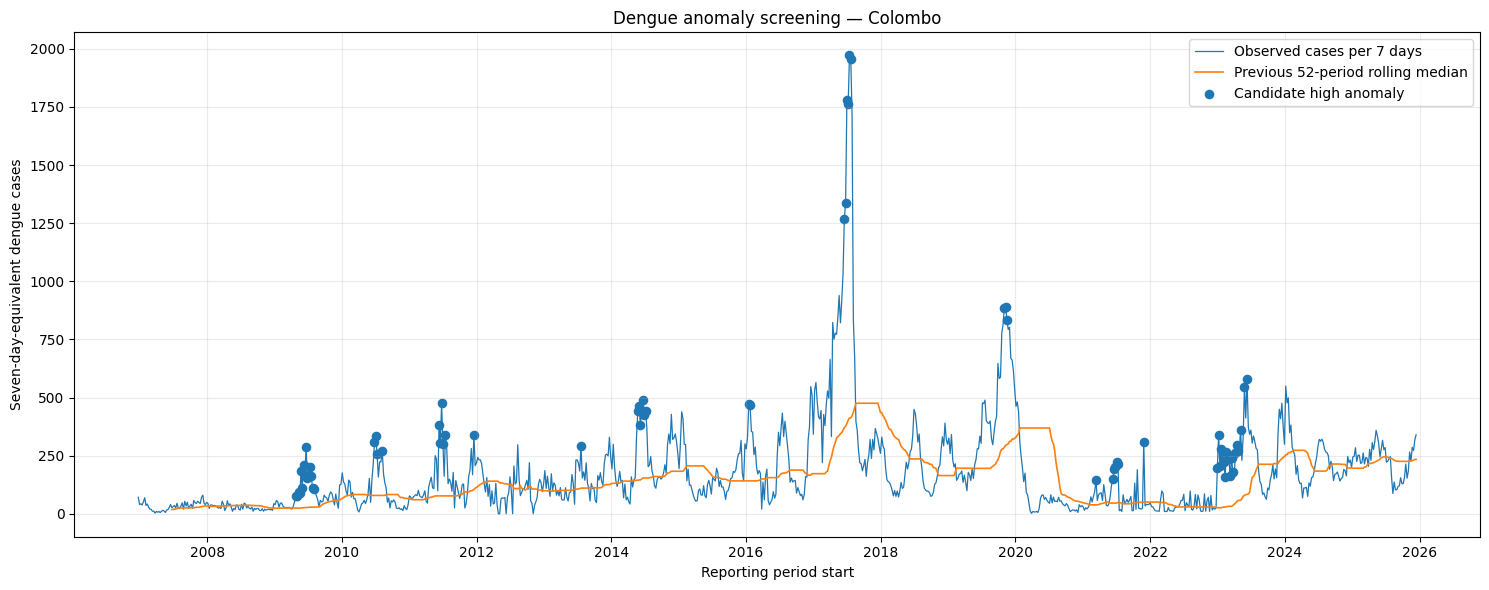

In [45]:
PLOT_DISTRICT = "colombo"

plot_data = df[df["district_key"] == PLOT_DISTRICT.lower()].copy()
if plot_data.empty:
    raise ValueError(f"No observations found for {PLOT_DISTRICT}")

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(
    plot_data["week_start"], plot_data["cases_per_7_days"],
    label="Observed cases per 7 days", linewidth=0.9
)
ax.plot(
    plot_data["week_start"], plot_data["baseline_median_52"],
    label="Previous 52-period rolling median", linewidth=1.2
)

points = plot_data[plot_data["candidate_high_anomaly"]]
ax.scatter(
    points["week_start"], points["cases_per_7_days"],
    label="Candidate high anomaly", s=35
)

ax.set_title(f"Dengue anomaly screening — {PLOT_DISTRICT.title()}")
ax.set_xlabel("Reporting period start")
ax.set_ylabel("Seven-day-equivalent dengue cases")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 11. Export scored observations, candidate anomalies, and method manifest

In [46]:
scored_path = OUTPUT_DIR / "dengue_anomaly_scored_weekly.csv"
candidate_path = OUTPUT_DIR / "candidate_high_dengue_anomalies.csv"
manifest_path = OUTPUT_DIR / "anomaly_detection_manifest.json"

df.to_csv(scored_path, index=False)
candidate_anomalies.to_csv(candidate_path, index=False)

manifest = {
    "project": "RiskWeave",
    "notebook": "07_dengue_anomaly_detection.ipynb",
    "input_file": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "method": "District-specific trailing rolling median and MAD",
    "signal": "Seven-day-equivalent dengue case count",
    "baseline_window_reporting_periods": WINDOW_PERIODS,
    "minimum_baseline_observations": MIN_BASELINE_PERIODS,
    "current_observation_excluded_from_baseline": True,
    "robust_score_formula": "(value - rolling_median) / (1.4826 * rolling_MAD)",
    "provisional_high_anomaly_threshold": PROVISIONAL_HIGH_ANOMALY_THRESHOLD,
    "zero_mad_policy": "Score left missing; not automatically flagged",
    "interpretation": "Candidate statistical anomalies only; not confirmed outbreaks",
    "rows_processed": int(len(df)),
    "districts": int(df["district_key"].nunique()),
    "candidate_high_anomalies": int(df["candidate_high_anomaly"].sum())
}

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=4)

print("Saved:", scored_path)
print("Saved:", candidate_path)
print("Saved:", manifest_path)
print("Candidate high anomalies:", manifest["candidate_high_anomalies"])

Saved: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\anomaly_detection\dengue_anomaly_scored_weekly.csv
Saved: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\anomaly_detection\candidate_high_dengue_anomalies.csv
Saved: c:\Users\Nethmi\Documents\GitHub\RiskWeave\outputs\anomaly_detection\anomaly_detection_manifest.json
Candidate high anomalies: 2061


In [48]:
# Make sure week_start is in datetime format
df["week_start"] = pd.to_datetime(df["week_start"])

# Extract ISO week number
df["week_of_year"] = (
    df["week_start"]
    .dt.isocalendar()
    .week
    .astype(int)
)

print("Week number column created successfully.")
display(df[["week_start", "week_of_year"]].head())

Week number column created successfully.


,week_start,week_of_year
0,2006-12-23,51
1,2006-12-30,52
2,2007-01-06,1
3,2007-01-13,2
4,2007-01-20,3


In [49]:
# Calculate national seasonal dengue pattern

national_seasonal_pattern = (
    df.groupby("week_of_year")["cases_per_7_days"]
      .agg(["mean", "median", "std", "count"])
      .reset_index()
)

display(national_seasonal_pattern)

,week_of_year,mean,median,std,count
0,1,41.821053,15.0,77.991071,475
1,2,41.349474,15.0,74.755974,475
2,3,40.204211,15.0,75.813746,475
3,4,33.966316,13.0,60.560000,475
4,5,32.204211,13.0,55.129139,475
5,6,29.031579,13.0,47.654845,475
6,7,25.987368,12.0,40.214088,475
7,8,25.288421,11.0,41.965464,475
8,9,23.130526,11.0,37.440414,475
9,10,23.949474,10.0,44.747882,475


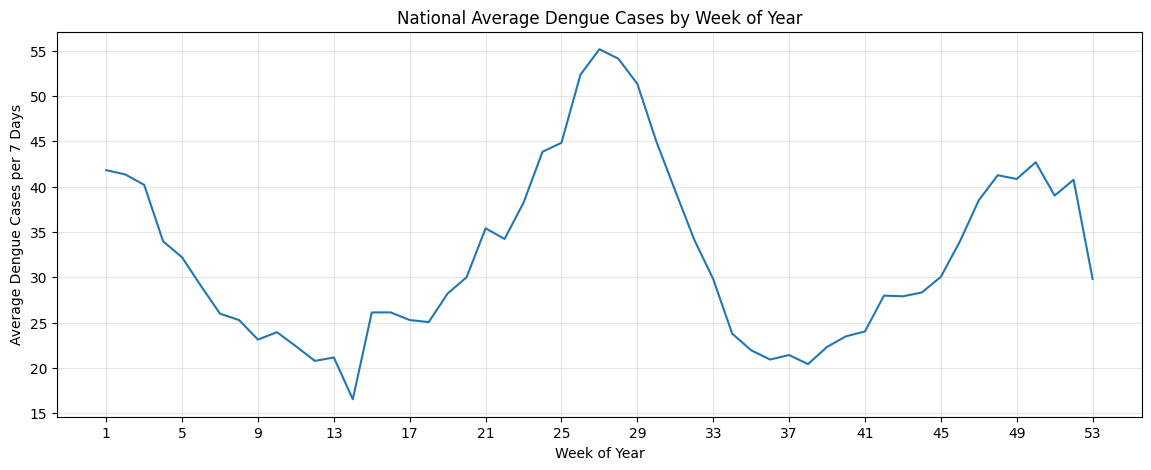

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    national_seasonal_pattern["week_of_year"],
    national_seasonal_pattern["mean"]
)

plt.xlabel("Week of Year")
plt.ylabel("Average Dengue Cases per 7 Days")
plt.title("National Average Dengue Cases by Week of Year")

plt.xticks(range(1, 54, 4))
plt.grid(alpha=0.3)

plt.show()

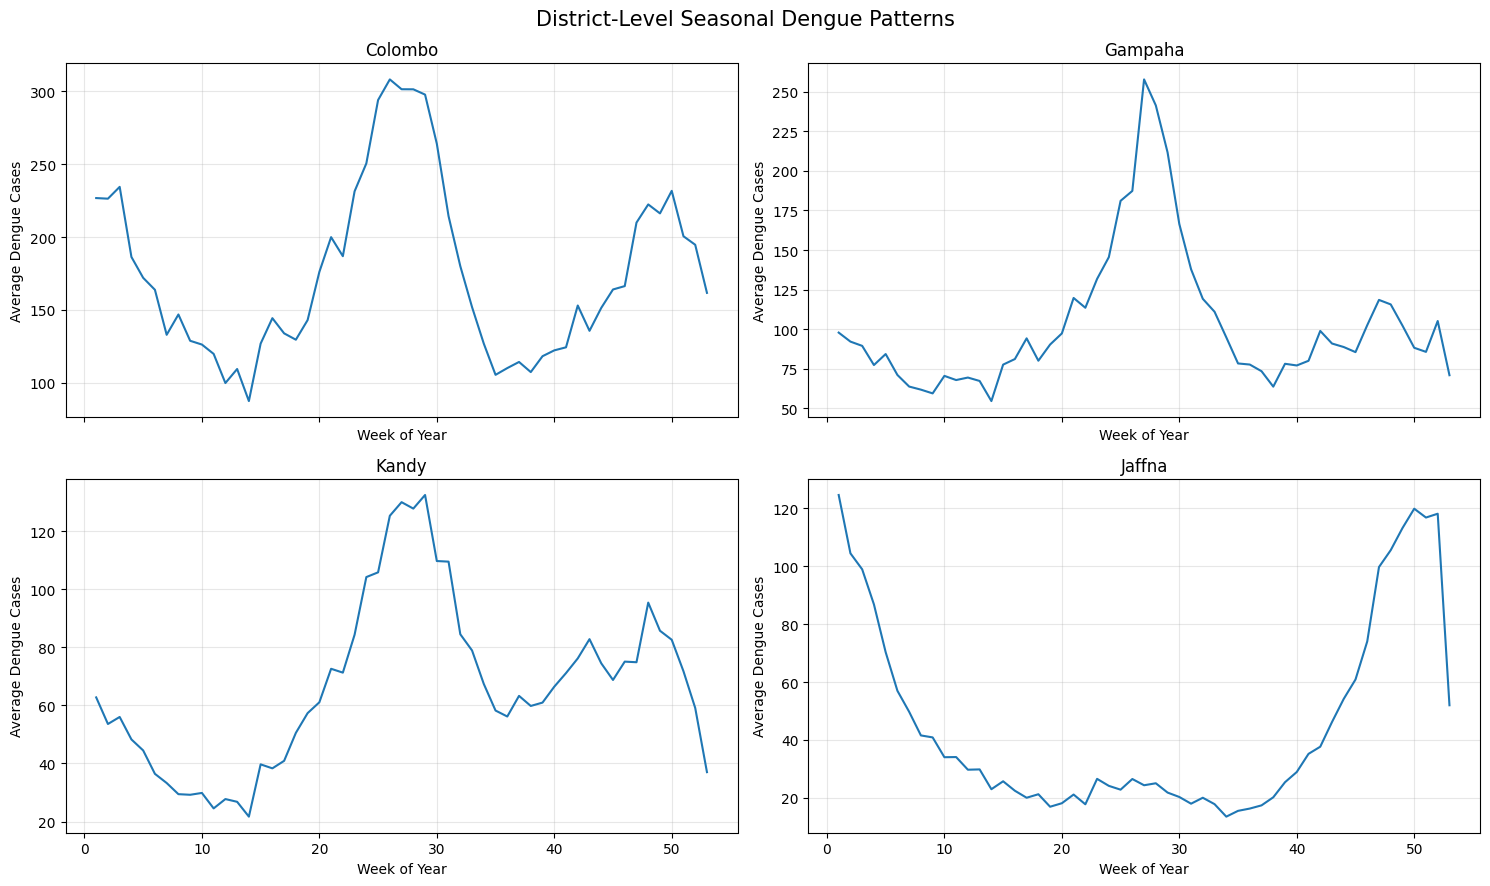

In [51]:
import matplotlib.pyplot as plt

selected_districts = [
    "colombo",
    "gampaha",
    "kandy",
    "jaffna"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 9),
    sharex=True
)

axes = axes.flatten()

for ax, district in zip(axes, selected_districts):

    district_data = df[
        df["district_key"] == district
    ]

    seasonal_data = (
        district_data
        .groupby("week_of_year")["cases_per_7_days"]
        .mean()
        .reset_index()
    )

    ax.plot(
        seasonal_data["week_of_year"],
        seasonal_data["cases_per_7_days"]
    )

    ax.set_title(district.title())
    ax.set_xlabel("Week of Year")
    ax.set_ylabel("Average Dengue Cases")
    ax.grid(alpha=0.3)

plt.suptitle(
    "District-Level Seasonal Dengue Patterns",
    fontsize=15
)

plt.tight_layout()
plt.show()

## 12. Limitations and next validation tasks

Before operational use or describing flags as outbreaks, RiskWeave needs further validation:

1. **Seasonality:** Compare this trailing baseline with a seasonally matched baseline, such as comparable epidemiological weeks in previous years.
2. **Threshold validation:** Test alternative thresholds and assess sensitivity and false-positive behaviour.
3. **Historical event review:** Compare candidate dates with official epidemiological reports and documented outbreak periods, where available.
4. **Surveillance changes:** Check whether reporting completeness, surveillance changes, or district definitions explain unusual values.
5. **District interpretation:** Review district-level results rather than applying one national case-count threshold.
6. **Dashboard language:** Until validated against authoritative outbreak criteria, use “candidate anomaly” or “unusual increase,” not “confirmed outbreak.”

### Completion checklist
- [ ] Data-quality checks reviewed
- [ ] Reporting-period normalization reviewed
- [ ] Historical baseline and robust scores calculated
- [ ] Candidate anomalies inspected
- [ ] District plots reviewed
- [ ] CSV outputs and manifest saved
- [ ] Candidate dates compared with official epidemiological evidence